In [ ]:
from google.colab import files
import zipfile
import io
import pandas as pd
import os

uploaded = files.upload()

zip_name = "College_Scorecard_Raw_Data_06032026.zip"

if zip_name not in uploaded:
    raise FileNotFoundError(f"没找到 {zip_name}，请确认上传文件名完全一致")

extract_dir = "/content/college_scorecard"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), 'r') as z:
    z.extractall(extract_dir)
    print("压缩包内容：")
    print(z.namelist()[:20])

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os

project_dir = "/content/drive/MyDrive/College_Scorecard_Project"
print(os.listdir(project_dir))

raw_dir = f"{project_dir}/raw_data"
if os.path.exists(raw_dir):
    print("raw_data 内容：")
    print(os.listdir(raw_dir))
else:
    print("raw_data 文件夹不存在，说明还没解压到 Drive")

['raw_data', 'CollegeScorecard_cleaned.csv', 'earnings_by_education.png', 'graduation_rate_vs_earnings.png']
raw_data 内容：
['College_Scorecard_Raw_Data_06032026', '__MACOSX']


In [8]:
import os

project_dir = "/content/drive/MyDrive/College_Scorecard_Project"
raw_dir = f"{project_dir}/raw_data"
data_dir = f"{raw_dir}/College_Scorecard_Raw_Data_06032026"

print(os.listdir(data_dir))

['MERGED2011_12_PP.csv', 'FieldOfStudyData1819_1920_PP.csv', 'MERGED1999_00_PP.csv', 'MERGED2006_07_PP.csv', 'MERGED2014_15_PP.csv', '.DS_Store', 'Most-Recent-Cohorts-Institution.csv', 'MERGED2003_04_PP.csv', 'MERGED1996_97_PP.csv', 'FieldOfStudyData1516_1617_PP.csv', 'Crosswalks', 'Most-Recent-Cohorts-Field-of-Study.csv', 'MERGED2012_13_PP.csv', 'MERGED2020_21_PP.csv', 'MERGED2005_06_PP.csv', 'MERGED2009_10_PP.csv', 'MERGED2023_24_PP.csv', 'FieldOfStudyData1617_1718_PP.csv', 'FieldOfStudyData2122_2223_PP.csv', 'MERGED2018_19_PP.csv', 'MERGED2025_26_PP.csv', 'MERGED2017_18_PP.csv', 'MERGED2000_01_PP.csv', 'FieldOfStudyData1718_1819_PP.csv', 'MERGED2001_02_PP.csv', 'MERGED2019_20_PP.csv', 'MERGED2024_25_PP.csv', 'MERGED2016_17_PP.csv', 'MERGED1997_98_PP.csv', 'MERGED1998_99_PP.csv', 'data.yaml', 'MERGED2004_05_PP.csv', 'MERGED2021_22_PP.csv', 'MERGED2002_03_PP.csv', 'FieldOfStudyData1920_2021_PP.csv', 'MERGED2015_16_PP.csv', 'MERGED2013_14_PP.csv', 'FieldOfStudyData2021_2122_PP.csv', 'M

In [9]:
csv_files = [f for f in os.listdir(data_dir) if f.endswith(".csv")]
print(csv_files)

['MERGED2011_12_PP.csv', 'FieldOfStudyData1819_1920_PP.csv', 'MERGED1999_00_PP.csv', 'MERGED2006_07_PP.csv', 'MERGED2014_15_PP.csv', 'Most-Recent-Cohorts-Institution.csv', 'MERGED2003_04_PP.csv', 'MERGED1996_97_PP.csv', 'FieldOfStudyData1516_1617_PP.csv', 'Most-Recent-Cohorts-Field-of-Study.csv', 'MERGED2012_13_PP.csv', 'MERGED2020_21_PP.csv', 'MERGED2005_06_PP.csv', 'MERGED2009_10_PP.csv', 'MERGED2023_24_PP.csv', 'FieldOfStudyData1617_1718_PP.csv', 'FieldOfStudyData2122_2223_PP.csv', 'MERGED2018_19_PP.csv', 'MERGED2025_26_PP.csv', 'MERGED2017_18_PP.csv', 'MERGED2000_01_PP.csv', 'FieldOfStudyData1718_1819_PP.csv', 'MERGED2001_02_PP.csv', 'MERGED2019_20_PP.csv', 'MERGED2024_25_PP.csv', 'MERGED2016_17_PP.csv', 'MERGED1997_98_PP.csv', 'MERGED1998_99_PP.csv', 'MERGED2004_05_PP.csv', 'MERGED2021_22_PP.csv', 'MERGED2002_03_PP.csv', 'FieldOfStudyData1920_2021_PP.csv', 'MERGED2015_16_PP.csv', 'MERGED2013_14_PP.csv', 'FieldOfStudyData2021_2122_PP.csv', 'MERGED2007_08_PP.csv', 'MERGED2008_09_PP.

In [10]:
import pandas as pd

csv_path = f"{data_dir}/{csv_files[0]}"
df = pd.read_csv(csv_path, low_memory=False)

print(df.shape)
print(df.columns.tolist()[:30])

(7746, 3308)
['UNITID', 'OPEID', 'OPEID6', 'INSTNM', 'CITY', 'STABBR', 'ZIP', 'ACCREDAGENCY', 'INSTURL', 'NPCURL', 'SCH_DEG', 'HCM2', 'MAIN', 'NUMBRANCH', 'PREDDEG', 'HIGHDEG', 'CONTROL', 'ST_FIPS', 'REGION', 'LOCALE', 'LOCALE2', 'LATITUDE', 'LONGITUDE', 'CCBASIC', 'CCUGPROF', 'CCSIZSET', 'HBCU', 'PBI', 'ANNHI', 'TRIBAL']


In [11]:
clean_path = f"{project_dir}/CollegeScorecard_cleaned.csv"
df.to_csv(clean_path, index=False)
print("已保存：", clean_path)

已保存： /content/drive/MyDrive/College_Scorecard_Project/CollegeScorecard_cleaned.csv


In [12]:
import pandas as pd

project_dir = "/content/drive/MyDrive/College_Scorecard_Project"
df_clean = pd.read_csv(f"{project_dir}/CollegeScorecard_cleaned.csv")
print(df_clean.shape)
print(df_clean.head())

/tmp/ipykernel_1160/2129600571.py:4: DtypeWarning: Columns (1433,1447,1489,1501,1502,1537,1540,1542,1547,1553,1554,1559,1560,1606,1614,1615,1636,1637,1638,1639,1640,1641,1642,1643,1644,1645,1646,1647,1648,1649,1650,1651,1652,1653,1658,1659,1693,1694,1729,1909,1910,1911,1912,1913) have mixed types. Specify dtype option on import or set low_memory=False.
  df_clean = pd.read_csv(f"{project_dir}/CollegeScorecard_cleaned.csv")


(7746, 3308)
   UNITID    OPEID  OPEID6                               INSTNM        CITY  \
0  100654   100200    1002             Alabama A & M University      Normal   
1  100663   105200    1052  University of Alabama at Birmingham  Birmingham   
2  100690  2503400   25034                   Amridge University  Montgomery   
3  100706   105500    1055  University of Alabama in Huntsville  Huntsville   
4  100724   100500    1005             Alabama State University  Montgomery   

  STABBR         ZIP  ACCREDAGENCY  INSTURL  NPCURL  ...  \
0     AL       35762           NaN      NaN     NaN  ...   
1     AL  35294-0110           NaN      NaN     NaN  ...   
2     AL  36117-3553           NaN      NaN     NaN  ...   
3     AL       35899           NaN      NaN     NaN  ...   
4     AL  36104-0271           NaN      NaN     NaN  ...   

   MD_EARN_WNE_INC1_P11  MD_EARN_WNE_INC2_P11  MD_EARN_WNE_INC3_P11  \
0                   NaN                   NaN                   NaN   
1        

In [13]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

project_dir = "/content/drive/MyDrive/College_Scorecard_Project"
df = pd.read_csv(f"{project_dir}/CollegeScorecard_cleaned.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_1160/765633312.py:6: DtypeWarning: Columns (1433,1447,1489,1501,1502,1537,1540,1542,1547,1553,1554,1559,1560,1606,1614,1615,1636,1637,1638,1639,1640,1641,1642,1643,1644,1645,1646,1647,1648,1649,1650,1651,1652,1653,1658,1659,1693,1694,1729,1909,1910,1911,1912,1913) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{project_dir}/CollegeScorecard_cleaned.csv")


(7746, 3308)
['UNITID', 'OPEID', 'OPEID6', 'INSTNM', 'CITY', 'STABBR', 'ZIP', 'ACCREDAGENCY', 'INSTURL', 'NPCURL', 'SCH_DEG', 'HCM2', 'MAIN', 'NUMBRANCH', 'PREDDEG', 'HIGHDEG', 'CONTROL', 'ST_FIPS', 'REGION', 'LOCALE', 'LOCALE2', 'LATITUDE', 'LONGITUDE', 'CCBASIC', 'CCUGPROF', 'CCSIZSET', 'HBCU', 'PBI', 'ANNHI', 'TRIBAL', 'AANAPII', 'HSI', 'NANTI', 'MENONLY', 'WOMENONLY', 'RELAFFIL', 'ADM_RATE', 'ADM_RATE_ALL', 'SATVR25', 'SATVR75', 'SATMT25', 'SATMT75', 'SATWR25', 'SATWR75', 'SATVRMID', 'SATMTMID', 'SATWRMID', 'ACTCM25', 'ACTCM75', 'ACTEN25', 'ACTEN75', 'ACTMT25', 'ACTMT75', 'ACTWR25', 'ACTWR75', 'ACTCMMID', 'ACTENMID', 'ACTMTMID', 'ACTWRMID', 'SAT_AVG', 'SAT_AVG_ALL', 'PCIP01', 'PCIP03', 'PCIP04', 'PCIP05', 'PCIP09', 'PCIP10', 'PCIP11', 'PCIP12', 'PCIP13', 'PCIP14', 'PCIP15', 'PCIP16', 'PCIP19', 'PCIP22', 'PCIP23', 'PCIP24', 'PCIP25', 'PCIP26', 'PCIP27', 'PCIP29', 'PCIP30', 'PCIP31', 'PCIP38', 'PCIP39', 'PCIP40', 'PCIP41', 'PCIP42', 'PCIP43', 'PCIP44', 'PCIP45', 'PCIP46', 'PCIP47', '

In [14]:
print(df.columns.tolist())

['UNITID', 'OPEID', 'OPEID6', 'INSTNM', 'CITY', 'STABBR', 'ZIP', 'ACCREDAGENCY', 'INSTURL', 'NPCURL', 'SCH_DEG', 'HCM2', 'MAIN', 'NUMBRANCH', 'PREDDEG', 'HIGHDEG', 'CONTROL', 'ST_FIPS', 'REGION', 'LOCALE', 'LOCALE2', 'LATITUDE', 'LONGITUDE', 'CCBASIC', 'CCUGPROF', 'CCSIZSET', 'HBCU', 'PBI', 'ANNHI', 'TRIBAL', 'AANAPII', 'HSI', 'NANTI', 'MENONLY', 'WOMENONLY', 'RELAFFIL', 'ADM_RATE', 'ADM_RATE_ALL', 'SATVR25', 'SATVR75', 'SATMT25', 'SATMT75', 'SATWR25', 'SATWR75', 'SATVRMID', 'SATMTMID', 'SATWRMID', 'ACTCM25', 'ACTCM75', 'ACTEN25', 'ACTEN75', 'ACTMT25', 'ACTMT75', 'ACTWR25', 'ACTWR75', 'ACTCMMID', 'ACTENMID', 'ACTMTMID', 'ACTWRMID', 'SAT_AVG', 'SAT_AVG_ALL', 'PCIP01', 'PCIP03', 'PCIP04', 'PCIP05', 'PCIP09', 'PCIP10', 'PCIP11', 'PCIP12', 'PCIP13', 'PCIP14', 'PCIP15', 'PCIP16', 'PCIP19', 'PCIP22', 'PCIP23', 'PCIP24', 'PCIP25', 'PCIP26', 'PCIP27', 'PCIP29', 'PCIP30', 'PCIP31', 'PCIP38', 'PCIP39', 'PCIP40', 'PCIP41', 'PCIP42', 'PCIP43', 'PCIP44', 'PCIP45', 'PCIP46', 'PCIP47', 'PCIP48', 'PCI

In [15]:
import os

base = "/content/drive/MyDrive/College_Scorecard_Project/raw_data/College_Scorecard_Raw_Data_06032026"
print(os.listdir(base))

csv_files = [f for f in os.listdir(base) if f.endswith(".csv")]
print("CSV files:", csv_files)

['MERGED2011_12_PP.csv', 'FieldOfStudyData1819_1920_PP.csv', 'MERGED1999_00_PP.csv', 'MERGED2006_07_PP.csv', 'MERGED2014_15_PP.csv', '.DS_Store', 'Most-Recent-Cohorts-Institution.csv', 'MERGED2003_04_PP.csv', 'MERGED1996_97_PP.csv', 'FieldOfStudyData1516_1617_PP.csv', 'Crosswalks', 'Most-Recent-Cohorts-Field-of-Study.csv', 'MERGED2012_13_PP.csv', 'MERGED2020_21_PP.csv', 'MERGED2005_06_PP.csv', 'MERGED2009_10_PP.csv', 'MERGED2023_24_PP.csv', 'FieldOfStudyData1617_1718_PP.csv', 'FieldOfStudyData2122_2223_PP.csv', 'MERGED2018_19_PP.csv', 'MERGED2025_26_PP.csv', 'MERGED2017_18_PP.csv', 'MERGED2000_01_PP.csv', 'FieldOfStudyData1718_1819_PP.csv', 'MERGED2001_02_PP.csv', 'MERGED2019_20_PP.csv', 'MERGED2024_25_PP.csv', 'MERGED2016_17_PP.csv', 'MERGED1997_98_PP.csv', 'MERGED1998_99_PP.csv', 'data.yaml', 'MERGED2004_05_PP.csv', 'MERGED2021_22_PP.csv', 'MERGED2002_03_PP.csv', 'FieldOfStudyData1920_2021_PP.csv', 'MERGED2015_16_PP.csv', 'MERGED2013_14_PP.csv', 'FieldOfStudyData2021_2122_PP.csv', 'M

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from scipy import stats

drive.mount('/content/drive')

project_dir = "/content/drive/MyDrive/College_Scorecard_Project"
raw_dir = f"{project_dir}/raw_data/College_Scorecard_Raw_Data_06032026"

csv_path = f"{raw_dir}/Most-Recent-Cohorts-Institution.csv"
df = pd.read_csv(csv_path, low_memory=False)

print(f"原始数据：{df.shape}")
print(f"列名前20个：{df.columns.tolist()[:20]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
原始数据：(6273, 3308)
列名前20个：['UNITID', 'OPEID', 'OPEID6', 'INSTNM', 'CITY', 'STABBR', 'ZIP', 'ACCREDAGENCY', 'INSTURL', 'NPCURL', 'SCH_DEG', 'HCM2', 'MAIN', 'NUMBRANCH', 'PREDDEG', 'HIGHDEG', 'CONTROL', 'ST_FIPS', 'REGION', 'LOCALE']


In [18]:
keep = ['UNITID','INSTNM','STATE','STABBR','CONTROL','HIGHDEG',
        'MD_EARN_WNE_P10','C150_4','UGDS','TUITIONFEE_IN','TUITIONFEE_OUT']
df = df[[c for c in keep if c in df.columns]].copy()

for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].replace(['PrivacySuppressed','NULL',''], np.nan)

num_cols = ['HIGHDEG','MD_EARN_WNE_P10','C150_4','UGDS','TUITIONFEE_IN','TUITIONFEE_OUT']
for c in num_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

df = df.dropna(subset=['HIGHDEG','MD_EARN_WNE_P10'])
df = df[(df['MD_EARN_WNE_P10'] > 0) & (df['MD_EARN_WNE_P10'] < 500000)]
df = df[df['HIGHDEG'].between(0, 4)]

deg_map = {0:'Non-degree',1:'Certificate',2:'Associate',3:'Bachelor',4:'Graduate'}
df['education_level'] = df['HIGHDEG'].map(deg_map)

clean_path = f"{project_dir}/CollegeScorecard_cleaned.csv"
df.to_csv(clean_path, index=False)
print(f"\n清洗完成：{df.shape}")
print(df['education_level'].value_counts())


清洗完成：(5127, 11)
education_level
Graduate       1639
Certificate    1336
Associate      1136
Bachelor        572
Non-degree      444
Name: count, dtype: int64


In [19]:
print("\n=== Median Earnings by Educational Attainment ===")
stats_table = df.groupby('education_level')['MD_EARN_WNE_P10'].agg(['count','median','mean','std'])
print(stats_table)


=== Median Earnings by Educational Attainment ===
                 count   median          mean           std
education_level                                            
Associate         1136  38379.5  39257.449824   9361.382752
Bachelor           572  42555.0  47947.533217  17319.301660
Certificate       1336  28349.5  31274.702844  12365.858557
Graduate          1639  53755.0  55801.651007  16591.454982
Non-degree         444  40092.0  43394.916667  15005.003949


In [20]:
groups = [g['MD_EARN_WNE_P10'].values for _, g in df.groupby('HIGHDEG')]
f_stat, p_val = stats.f_oneway(*groups)
print(f"\nANOVA: F={f_stat:.2f}, p={p_val:.6f}")


ANOVA: F=598.13, p=0.000000


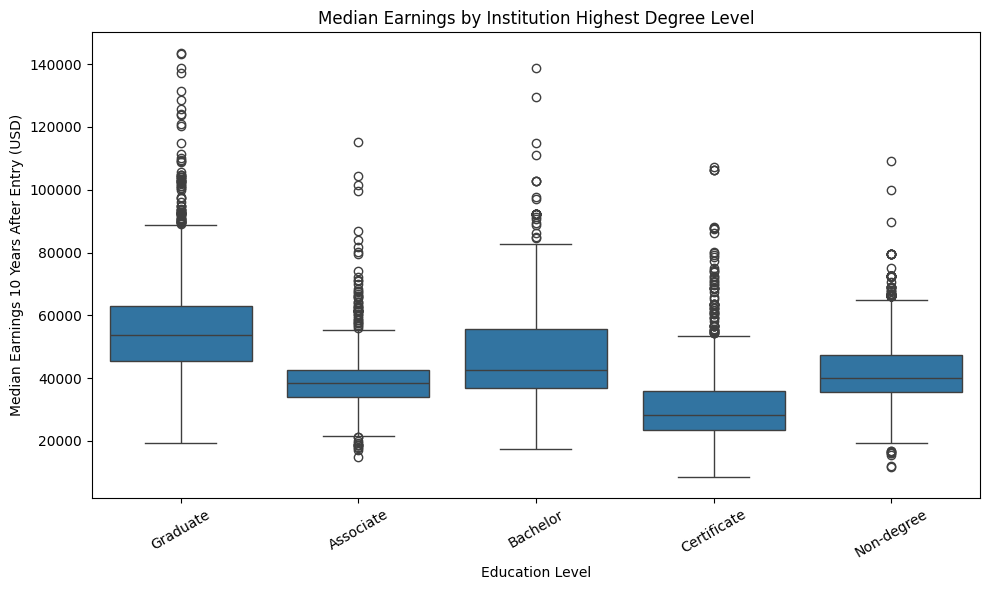

图表已保存：/content/drive/MyDrive/College_Scorecard_Project/earnings_by_education.png


In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='education_level', y='MD_EARN_WNE_P10')
plt.title('Median Earnings by Institution Highest Degree Level')
plt.xlabel('Education Level')
plt.ylabel('Median Earnings 10 Years After Entry (USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plot_path = f"{project_dir}/earnings_by_education.png"
plt.savefig(plot_path, dpi=150)
plt.show()
print(f"图表已保存：{plot_path}")

Correlation (C150_4 vs MD_EARN_WNE_P10): 0.5529
样本量 n = 2105


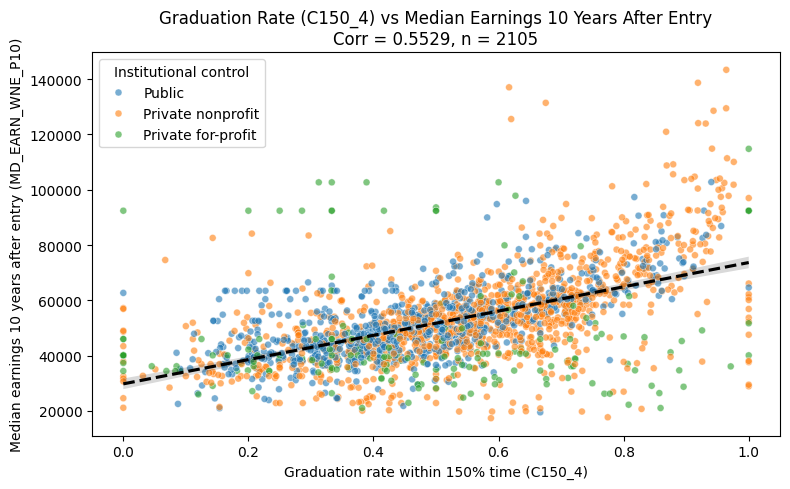

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

tmp = df[['C150_4', 'MD_EARN_WNE_P10', 'CONTROL']].dropna()
# 相关系数
corr = tmp['C150_4'].corr(tmp['MD_EARN_WNE_P10'])
print("Correlation (C150_4 vs MD_EARN_WNE_P10):", round(corr, 4))
print("样本量 n =", len(tmp))

control_map = {1: 'Public', 2: 'Private nonprofit', 3: 'Private for-profit'}
tmp['control_label'] = tmp['CONTROL'].map(control_map)

# 散点图
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=tmp,
    x='C150_4',
    y='MD_EARN_WNE_P10',
    hue='control_label',
    alpha=0.6,
    s=25
)

sns.regplot(
    data=tmp,
    x='C150_4',
    y='MD_EARN_WNE_P10',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--'}
)

plt.title(f'Graduation Rate (C150_4) vs Median Earnings 10 Years After Entry\nCorr = {corr:.4f}, n = {len(tmp)}')
plt.xlabel('Graduation rate within 150% time (C150_4)')
plt.ylabel('Median earnings 10 years after entry (MD_EARN_WNE_P10)')
plt.legend(title='Institutional control')
plt.tight_layout()
plt.savefig('/content/graduation_rate_vs_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
from scipy.stats import pearsonr
# 显著性检验
r, p = pearsonr(tmp['C150_4'], tmp['MD_EARN_WNE_P10'])
print("Pearson r =", round(r, 4))
print("p-value =", p)

Pearson r = 0.5529
p-value = 7.576039540010826e-169
